# Adaptive Temporal Detection of Denial-of-Wallet Attacks

## Notebook 02 — Temporal Deep Learning, Distribution-Shift Adaptation and Final Evaluation

This notebook performs:

1. Loading and verifying the 30-timestep, 26-feature sequences generated by Notebook 1.
2. Binary class distribution and numerical integrity verification.
3. Development and training of three temporal deep-learning models: LSTM, GRU and TCN.
4. Comparison of models using Accuracy, Precision, Recall, F1-score, MCC, FPR, FNR, ROC-AUC and PR-AUC.
5. Evaluation of training time, inference latency and model parameter count.
6. Selection of a suitable temporal model using validation performance and computational efficiency.
7. Kolmogorov–Smirnov-based workload distribution-shift detection between training and held-out validation functions.
8. Supplementary fine-tuning of the selected model using labeled validation-function sequences.
9. Final comparison of the original and adapted model on the same held-out test functions.
10. Generation of evaluation tables, confusion matrices, training curves, comparison visualizations and saved results.

**Evaluation Strategy:** The experiment uses FunctionId-disjoint supervised binary classification. Distribution-shift detection and adaptation are evaluated across function groups rather than through globally chronological future-workload periods.

In [1]:
import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LSTM,
    GRU,
    Conv1D,
    GlobalAveragePooling1D,
    Add,
    Activation,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.21.0
Libraries imported successfully.


In [2]:

SEED = 42

# TensorFlow, NumPy and Python random seeds
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Enable deterministic TensorFlow operations
tf.config.experimental.enable_op_determinism()

print("=" * 60)
print("REPRODUCIBILITY CONFIGURATION")
print("=" * 60)
print("Random seed:", SEED)
print("TensorFlow version:", tf.__version__)
print("Deterministic TensorFlow operations: Enabled")
print("=" * 60)


REPRODUCIBILITY CONFIGURATION
Random seed: 42
TensorFlow version: 2.21.0
Deterministic TensorFlow operations: Enabled


In [3]:
PROJECT_ROOT = Path(".")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SEQUENCE_DIR = PROCESSED_DIR / "sequences"

MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

for directory in [
    MODELS_DIR,
    RESULTS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT.resolve())
print("Sequence directory exists:", SEQUENCE_DIR.exists())

Project root: C:\MATT PROJECT\DoW Project FULL IMP
Sequence directory exists: True


In [4]:
required_files = [
    SEQUENCE_DIR / "X_train.npy",
    SEQUENCE_DIR / "y_train.npy",
    SEQUENCE_DIR / "X_val.npy",
    SEQUENCE_DIR / "y_val.npy",
    SEQUENCE_DIR / "X_test.npy",
    SEQUENCE_DIR / "y_test.npy",
    PROCESSED_DIR / "sequence_metadata.json",
    PROCESSED_DIR / "final_feature_names.csv"
]

all_files_exist = True

for file_path in required_files:

    exists = file_path.exists()

    print(
        f"{file_path.name:<30} -> {exists}"
    )

    if not exists:
        all_files_exist = False

assert all_files_exist, (
    "One or more required Notebook 1 outputs are missing."
)

print("\nAll required files are available.")

X_train.npy                    -> True
y_train.npy                    -> True
X_val.npy                      -> True
y_val.npy                      -> True
X_test.npy                     -> True
y_test.npy                     -> True
sequence_metadata.json         -> True
final_feature_names.csv        -> True

All required files are available.


In [5]:
X_train = np.load(
    SEQUENCE_DIR / "X_train.npy"
)

y_train = np.load(
    SEQUENCE_DIR / "y_train.npy"
)

X_val = np.load(
    SEQUENCE_DIR / "X_val.npy"
)

y_val = np.load(
    SEQUENCE_DIR / "y_val.npy"
)

X_test = np.load(
    SEQUENCE_DIR / "X_test.npy"
)

y_test = np.load(
    SEQUENCE_DIR / "y_test.npy"
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (124596, 30, 26)
y_train: (124596,)
X_val: (29131, 30, 26)
y_val: (29131,)
X_test: (30768, 30, 26)
y_test: (30768,)


Load Metadata

In [6]:
metadata_path = (
    PROCESSED_DIR
    / "sequence_metadata.json"
)

with open(
    metadata_path,
    "r"
) as file:

    metadata = json.load(file)

metadata

{'project': 'Adaptive Temporal DoW Detection',
 'target': 'bot',
 'sequence_length': 30,
 'numeric_features': ['RTT',
  'InvocationDelay',
  'ResponseDelay',
  'FunctionDuration',
  'ActiveFunctionsAtRequest',
  'ActiveFunctionsAtResponse',
  'maxcpu',
  'avgcpu',
  'p95maxcpu',
  'vmcorecountbucket',
  'vmmemorybucket',
  'InterArrivalTime',
  'FunctionInvocationsPerMinute',
  'InvocationsLast5Min',
  'TotalDelay',
  'TotalProcessingTime',
  'ActiveFunctionChange',
  'CPU_Spread'],
 'categorical_features': ['functionTrigger', 'vmcategory'],
 'final_encoded_feature_count': 26,
 'final_feature_names': ['numeric__RTT',
  'numeric__InvocationDelay',
  'numeric__ResponseDelay',
  'numeric__FunctionDuration',
  'numeric__ActiveFunctionsAtRequest',
  'numeric__ActiveFunctionsAtResponse',
  'numeric__maxcpu',
  'numeric__avgcpu',
  'numeric__p95maxcpu',
  'numeric__vmcorecountbucket',
  'numeric__vmmemorybucket',
  'numeric__InterArrivalTime',
  'numeric__FunctionInvocationsPerMinute',
  'num

Load Final Feature Names

In [7]:
feature_names_df = pd.read_csv(
    PROCESSED_DIR
    / "final_feature_names.csv"
)

feature_names = (
    feature_names_df["Feature"]
    .tolist()
)

print(
    "Number of encoded features:",
    len(feature_names)
)

feature_names[:10]

Number of encoded features: 26


['numeric__RTT',
 'numeric__InvocationDelay',
 'numeric__ResponseDelay',
 'numeric__FunctionDuration',
 'numeric__ActiveFunctionsAtRequest',
 'numeric__ActiveFunctionsAtResponse',
 'numeric__maxcpu',
 'numeric__avgcpu',
 'numeric__p95maxcpu',
 'numeric__vmcorecountbucket']

Input Dimensions

In [8]:

N_TIMESTEPS = X_train.shape[1]
N_FEATURES = X_train.shape[2]

print("Sequence length:", N_TIMESTEPS)
print("Features per timestep:", N_FEATURES)

# Check dimensions across splits
assert X_val.shape[1:] == X_train.shape[1:]
assert X_test.shape[1:] == X_train.shape[1:]

# Verify exact feature count
assert N_FEATURES == len(feature_names), (
    f"Feature mismatch: arrays contain {N_FEATURES}, "
    f"but feature names contain {len(feature_names)}."
)

assert N_FEATURES == metadata["final_encoded_feature_count"], (
    "Array dimensions do not match saved metadata."
)

assert N_TIMESTEPS == metadata["sequence_length"], (
    "Sequence length does not match saved metadata."
)

# Check feature names have not changed
assert feature_names == metadata["final_feature_names"], (
    "Feature list differs from preprocessing metadata."
)

print("\nFeature count validation: PASSED")
print("Sequence length validation: PASSED")
print("Metadata consistency: PASSED")


Sequence length: 30
Features per timestep: 26

Feature count validation: PASSED
Sequence length validation: PASSED
Metadata consistency: PASSED


Final Class Distribution Check

In [9]:
def get_class_counts(y):

    return {
        "Normal": int(
            np.sum(y == 0)
        ),
        "DoW": int(
            np.sum(y == 1)
        )
    }


class_check = pd.DataFrame([
    {
        "Split": "Train",
        **get_class_counts(y_train)
    },
    {
        "Split": "Validation",
        **get_class_counts(y_val)
    },
    {
        "Split": "Test",
        **get_class_counts(y_test)
    }
])

class_check

,Split,Normal,DoW
0,Train,35329,89267
1,Validation,8865,20266
2,Test,10534,20234


Assert Both Classes Exist

In [10]:

# ============================================================
# BINARY CLASSIFICATION READINESS CHECK
# FunctionId-Disjoint Cross-Function Evaluation
# ============================================================

import numpy as np

print("=" * 70)
print("BINARY CLASSIFICATION READINESS CHECK")
print("=" * 70)

expected_shapes = {
    "Train": (124596, 30, 26),
    "Validation": (29131, 30, 26),
    "Test": (30768, 30, 26)
}

datasets = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

for name, (X, y) in datasets.items():

    print(f"\n{name}")
    print("X shape:", X.shape)
    print("y shape:", y.shape)

    assert X.shape == expected_shapes[name], (
        f"{name} shape mismatch. "
        "Check Notebook 1 generated files."
    )

    assert len(X) == len(y), (
        f"{name} X/y sample counts differ."
    )

    labels, counts = np.unique(
        y,
        return_counts=True
    )

    class_distribution = dict(
        zip(labels.tolist(), counts.tolist())
    )

    print("Class distribution:", class_distribution)

    assert set(labels.tolist()) == {0, 1}, (
        f"{name} must contain both binary classes."
    )

    assert np.isfinite(X).all(), (
        f"{name} contains NaN or infinite values."
    )

print("\nChecking evaluation metadata...")

assert metadata["group_column"] == "FunctionId", (
    "Expected FunctionId-disjoint evaluation."
)

assert metadata["globally_chronological"] is False, (
    "Unexpected chronological evaluation metadata."
)

assert metadata["binary_evaluation_ready"] is True

assert N_TIMESTEPS == 30
assert N_FEATURES == 26

print("\nAll sequence datasets verified.")
print("Binary classification readiness: PASSED")
print("FunctionId-disjoint evaluation: CONFIRMED")
print("Input shape:", (N_TIMESTEPS, N_FEATURES))

print("\nIMPORTANT:")
print("This experiment evaluates held-out functions.")
print("It is not globally chronological future-time evaluation.")


BINARY CLASSIFICATION READINESS CHECK

Train
X shape: (124596, 30, 26)
y shape: (124596,)
Class distribution: {0: 35329, 1: 89267}

Validation
X shape: (29131, 30, 26)
y shape: (29131,)
Class distribution: {0: 8865, 1: 20266}

Test
X shape: (30768, 30, 26)
y shape: (30768,)
Class distribution: {0: 10534, 1: 20234}

Checking evaluation metadata...

All sequence datasets verified.
Binary classification readiness: PASSED
FunctionId-disjoint evaluation: CONFIRMED
Input shape: (30, 26)

IMPORTANT:
This experiment evaluates held-out functions.
It is not globally chronological future-time evaluation.


Verify NaN and Infinite Values

In [11]:
datasets = {
    "X_train": X_train,
    "X_val": X_val,
    "X_test": X_test
}

for name, data in datasets.items():

    print(
        name,
        "| NaN:",
        np.isnan(data).sum(),
        "| Inf:",
        np.isinf(data).sum()
    )

X_train | NaN: 0 | Inf: 0
X_val | NaN: 0 | Inf: 0
X_test | NaN: 0 | Inf: 0


Class Distribution Visualization

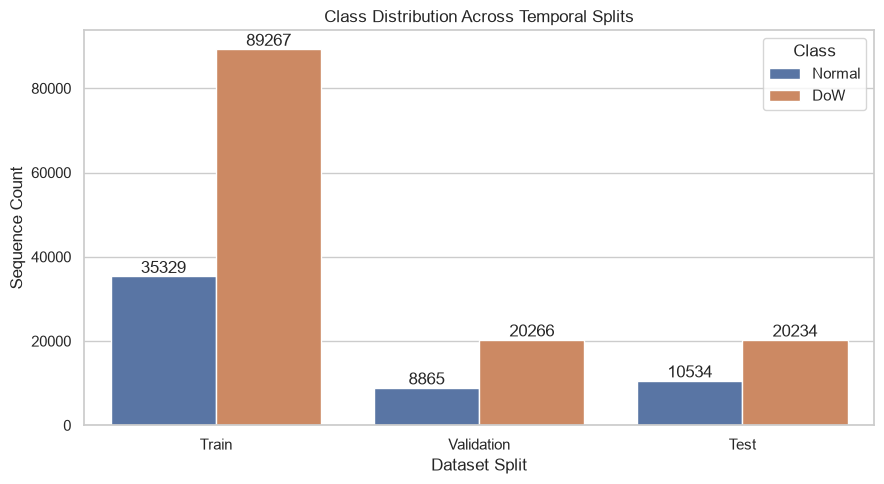

In [12]:
plot_class_df = class_check.melt(
    id_vars="Split",
    var_name="Class",
    value_name="Count"
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=plot_class_df,
    x="Split",
    y="Count",
    hue="Class"
)

plt.title(
    "Class Distribution Across Temporal Splits"
)

plt.xlabel("Dataset Split")
plt.ylabel("Sequence Count")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Compute Training Class Weights

In [13]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight
    in zip(classes, weights)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: 1.7633672054119844, 1: 0.6978838764605061}



Common Training Settings

In [14]:
EPOCHS = 30
BATCH_SIZE = 256
LEARNING_RATE = 0.001

print("Maximum epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Maximum epochs: 30
Batch size: 256
Learning rate: 0.001


Common Callbacks Function

In [15]:
def get_callbacks(model_name):

    checkpoint_path = (
        MODELS_DIR
        / f"{model_name.lower()}_best.keras"
    )

    return [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

Common Evaluation Function

In [16]:
def evaluate_binary_model(
    model,
    X,
    y,
    model_name
):

    start_time = time.perf_counter()

    probabilities = (
        model.predict(
            X,
            verbose=0
        )
        .ravel()
    )

    inference_time = (
        time.perf_counter()
        - start_time
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y,
        predictions
    )

    precision = precision_score(
        y,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y,
        predictions,
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y,
        predictions
    )

    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    ).ravel()

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0.0
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else 0.0
    )

    roc_auc = roc_auc_score(
        y,
        probabilities
    )

    pr_auc = average_precision_score(
        y,
        probabilities
    )

    latency_ms = (
        inference_time
        / len(X)
        * 1000
    )

    metrics = {

        "Model": model_name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1": f1,

        "MCC": mcc,

        "FPR": fpr,

        "FNR": fnr,

        "ROC_AUC": roc_auc,

        "PR_AUC": pr_auc,

        "Total_Inference_Time_sec":
            inference_time,

        "Latency_per_Sample_ms":
            latency_ms,

        "Parameters":
            int(model.count_params())
    }

    return (
        metrics,
        predictions,
        probabilities
    )

Training History Function

In [17]:
def plot_training_history(
    history,
    model_name
):

    history_df = pd.DataFrame(
        history.history
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history_df["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(
        f"{model_name} Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["loss"],
        label="Training Loss"
    )

    plt.plot(
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"{model_name} Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")

    plt.legend()

    plt.tight_layout()
    plt.show()

Confusion Matrix Function

In [18]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    model_name
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "Normal",
            "DoW"
        ],
        yticklabels=[
            "Normal",
            "DoW"
        ]
    )

    plt.title(
        f"{model_name} Confusion Matrix"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.xticks(rotation=0)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

# LSTM Model

Build LSTM

In [19]:
def build_lstm_model():

    model = Sequential([

        Input(
            shape=(
                N_TIMESTEPS,
                N_FEATURES
            )
        ),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.30),

        LSTM(32),

        Dropout(0.30),

        Dense(
            32,
            activation="relu"
        ),

        Dropout(0.20),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

LSTM Summary

In [20]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

lstm_model = build_lstm_model()
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        23,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,801 (143.75 KB)

 Trainable params: 36,801 (143.75 KB)

 Non-trainable params: 0 (0.00 B)

Train LSTM

In [21]:
start_time = time.perf_counter()

lstm_history = lstm_model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weights,

    callbacks=get_callbacks(
        "LSTM"
    ),

    verbose=1
)

lstm_training_time = (
    time.perf_counter()
    - start_time
)

print(
    "LSTM training time:",
    round(
        lstm_training_time,
        2
    ),
    "seconds"
)

Epoch 1/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.9518 - loss: 0.1726
Epoch 1: val_loss improved from None to 0.25876, saving model to models\lstm_best.keras

Epoch 1: finished saving model to models\lstm_best.keras
487/487 ━━━━━━━━━━━━━━━━━━━━ 69s 135ms/step - accuracy: 0.9518 - loss: 0.1726 - val_accuracy: 0.8611 - val_loss: 0.2588 - learning_rate: 0.0010
Epoch 2/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9638 - loss: 0.1007
Epoch 2: val_loss improved from 0.25876 to 0.19839, saving model to models\lstm_best.keras

Epoch 2: finished saving model to models\lstm_best.keras
487/487 ━━━━━━━━━━━━━━━━━━━━ 89s 150ms/step - accuracy: 0.9638 - loss: 0.1007 - val_accuracy: 0.8649 - val_loss: 0.1984 - learning_rate: 0.0010
Epoch 3/30
486/487 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.9667 - loss: 0.0861
Epoch 3: val_loss improved from 0.19839 to 0.18224, saving model to models\lstm_best.keras

Epoch 3: finished saving model to models\lstm_best.keras
487/

LSTM Training Curves

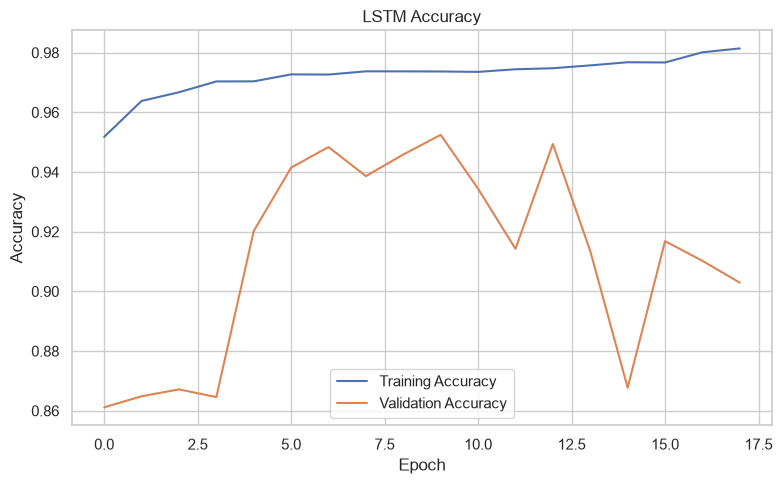

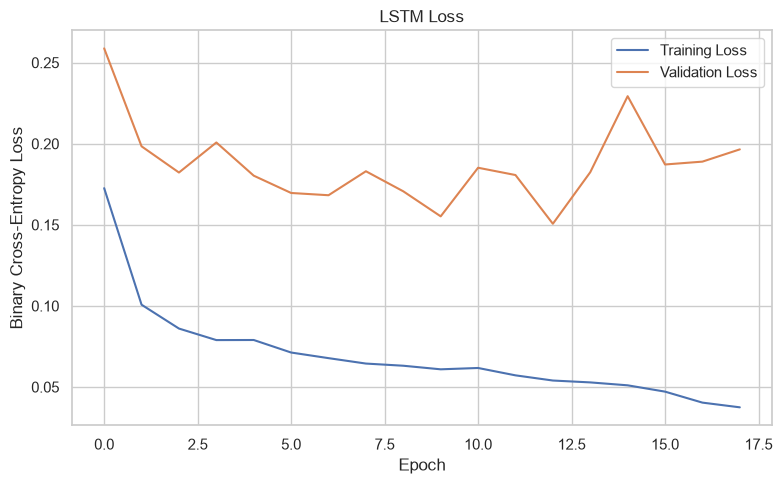

In [22]:
plot_training_history(
    lstm_history,
    "LSTM"
)

LSTM Validation Evaluation

In [23]:
(
    lstm_metrics,
    lstm_val_pred,
    lstm_val_prob
) = evaluate_binary_model(
    lstm_model,
    X_val,
    y_val,
    "LSTM"
)

lstm_metrics[
    "Training_Time_sec"
] = lstm_training_time

pd.DataFrame(
    [lstm_metrics]
).T

,0
Model,LSTM
Accuracy,0.949401
Precision,0.972683
Recall,0.954061
F1,0.963282
MCC,0.882377
FPR,0.061252
FNR,0.045939
ROC_AUC,0.988708
PR_AUC,0.994523


LSTM Classification Report

In [24]:
print(
    classification_report(
        y_val,
        lstm_val_pred,
        labels=[0, 1],
        target_names=[
            "Normal",
            "DoW"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal     0.8994    0.9387    0.9186      8865
         DoW     0.9727    0.9541    0.9633     20266

    accuracy                         0.9494     29131
   macro avg     0.9360    0.9464    0.9410     29131
weighted avg     0.9504    0.9494    0.9497     29131



LSTM Confusion Matrix

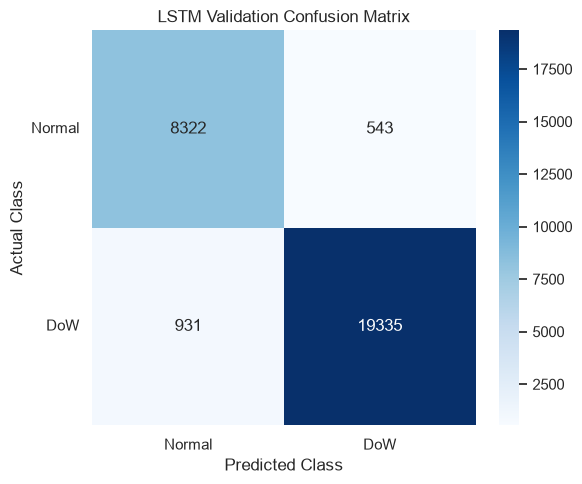

In [25]:
plot_confusion_matrix(
    y_val,
    lstm_val_pred,
    "LSTM Validation"
)

# GRU Model

Build GRU

In [26]:
def build_gru_model():

    model = Sequential([

        Input(
            shape=(
                N_TIMESTEPS,
                N_FEATURES
            )
        ),

        GRU(
            64,
            return_sequences=True
        ),

        Dropout(0.30),

        GRU(32),

        Dropout(0.30),

        Dense(
            32,
            activation="relu"
        ),

        Dropout(0.20),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

GRU Summary

In [27]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(43)

gru_model = build_gru_model()
gru_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,161 (110.00 KB)

 Trainable params: 28,161 (110.00 KB)

 Non-trainable params: 0 (0.00 B)

Train GRU

In [28]:
start_time = time.perf_counter()

gru_history = gru_model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weights,

    callbacks=get_callbacks(
        "GRU"
    ),

    verbose=1
)

gru_training_time = (
    time.perf_counter()
    - start_time
)

print(
    "GRU training time:",
    round(
        gru_training_time,
        2
    ),
    "seconds"
)

Epoch 1/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9516 - loss: 0.1858
Epoch 1: val_loss improved from None to 0.21288, saving model to models\gru_best.keras

Epoch 1: finished saving model to models\gru_best.keras
487/487 ━━━━━━━━━━━━━━━━━━━━ 38s 73ms/step - accuracy: 0.9516 - loss: 0.1858 - val_accuracy: 0.9444 - val_loss: 0.2129 - learning_rate: 0.0010
Epoch 2/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.9612 - loss: 0.1152
Epoch 2: val_loss improved from 0.21288 to 0.18784, saving model to models\gru_best.keras

Epoch 2: finished saving model to models\gru_best.keras
487/487 ━━━━━━━━━━━━━━━━━━━━ 76s 155ms/step - accuracy: 0.9612 - loss: 0.1152 - val_accuracy: 0.9409 - val_loss: 0.1878 - learning_rate: 0.0010
Epoch 3/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.9670 - loss: 0.0912
Epoch 3: val_loss improved from 0.18784 to 0.15977, saving model to models\gru_best.keras

Epoch 3: finished saving model to models\gru_best.keras
487/487 ━━━━

GRU Training Curves

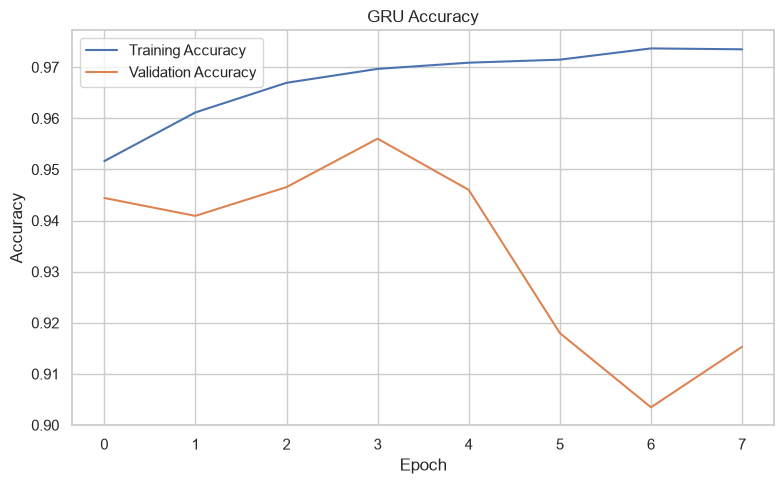

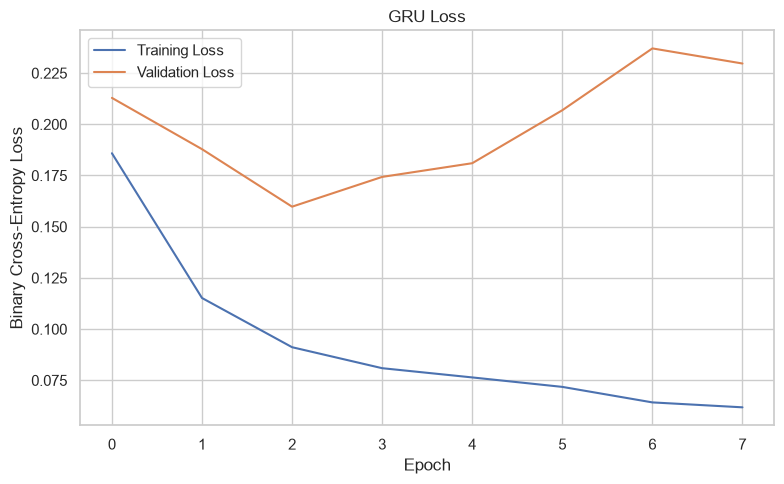

In [29]:
plot_training_history(
    gru_history,
    "GRU"
)

GRU Validation Evaluation

In [30]:
(
    gru_metrics,
    gru_val_pred,
    gru_val_prob
) = evaluate_binary_model(
    gru_model,
    X_val,
    y_val,
    "GRU"
)

gru_metrics[
    "Training_Time_sec"
] = gru_training_time

pd.DataFrame(
    [gru_metrics]
).T

,0
Model,GRU
Accuracy,0.946552
Precision,0.935762
Recall,0.991217
F1,0.962691
MCC,0.873253
FPR,0.155556
FNR,0.008783
ROC_AUC,0.981393
PR_AUC,0.9908


GRU Classification Report

In [31]:
print(
    classification_report(
        y_val,
        gru_val_pred,
        labels=[0, 1],
        target_names=[
            "Normal",
            "DoW"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal     0.9768    0.8444    0.9058      8865
         DoW     0.9358    0.9912    0.9627     20266

    accuracy                         0.9466     29131
   macro avg     0.9563    0.9178    0.9342     29131
weighted avg     0.9482    0.9466    0.9454     29131



GRU Confusion Matrix

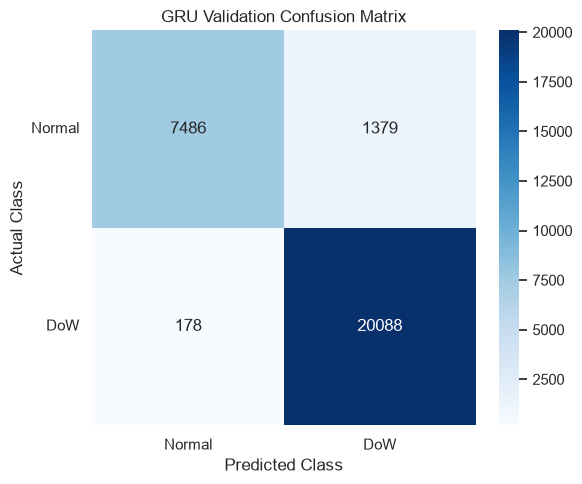

In [32]:
plot_confusion_matrix(
    y_val,
    gru_val_pred,
    "GRU Validation"
)

# Temporal Convolutional Network (TCN)

TCN Residual Block

In [33]:
def tcn_residual_block(
    x,
    filters,
    kernel_size,
    dilation_rate,
    dropout_rate=0.20
):

    residual = x

    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate
    )(x)

    x = BatchNormalization()(x)

    if residual.shape[-1] != filters:

        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same"
        )(residual)

    x = Add()([
        x,
        residual
    ])

    x = Activation(
        "relu"
    )(x)

    return x

Build TCN

In [34]:
def build_tcn_model():

    inputs = Input(
        shape=(
            N_TIMESTEPS,
            N_FEATURES
        )
    )

    x = inputs

    for dilation_rate in [
        1,
        2,
        4,
        8
    ]:

        x = tcn_residual_block(
            x=x,
            filters=64,
            kernel_size=3,
            dilation_rate=dilation_rate,
            dropout_rate=0.20
        )

    x = GlobalAveragePooling1D()(x)

    x = Dense(
        32,
        activation="relu"
    )(x)

    x = Dropout(
        0.20
    )(x)

    outputs = Dense(
        1,
        activation="sigmoid"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs
    )

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

TCN Summary

In [35]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(44)

tcn_model = build_tcn_model()
tcn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 64)    │      5,056 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 30, 64)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 30, 64)    │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 64)    │     12,352 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 64)    │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 30, 64)    │      1,728 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 64)    │          0 │ batch_normalizat… │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 30, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 30, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 64)    │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 30, 64)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 64)    │          0 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 30, 64)    │     12,352 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 64)    │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 64)    │          0 │ batch_normalizat… │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 30, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 30, 64)    │     12,352 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 97,409 (380.50 KB)

 Trainable params: 96,385 (376.50 KB)

 Non-trainable params: 1,024 (4.00 KB)

Train TCN

In [36]:
start_time = time.perf_counter()

tcn_history = tcn_model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weights,

    callbacks=get_callbacks(
        "TCN"
    ),

    verbose=1
)

tcn_training_time = (
    time.perf_counter()
    - start_time
)

print(
    "TCN training time:",
    round(
        tcn_training_time,
        2
    ),
    "seconds"
)

Epoch 1/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9472 - loss: 0.1587
Epoch 1: val_loss improved from None to 0.35948, saving model to models\tcn_best.keras

Epoch 1: finished saving model to models\tcn_best.keras
487/487 ━━━━━━━━━━━━━━━━━━━━ 146s 257ms/step - accuracy: 0.9472 - loss: 0.1587 - val_accuracy: 0.8528 - val_loss: 0.3595 - learning_rate: 0.0010
Epoch 2/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.9675 - loss: 0.0900
Epoch 2: val_loss improved from 0.35948 to 0.19838, saving model to models\tcn_best.keras

Epoch 2: finished saving model to models\tcn_best.keras
487/487 ━━━━━━━━━━━━━━━━━━━━ 117s 240ms/step - accuracy: 0.9675 - loss: 0.0900 - val_accuracy: 0.9097 - val_loss: 0.1984 - learning_rate: 0.0010
Epoch 3/30
487/487 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9706 - loss: 0.0758
Epoch 3: val_loss improved from 0.19838 to 0.16142, saving model to models\tcn_best.keras

Epoch 3: finished saving model to models\tcn_best.keras
487/487 

TCN Training Curves

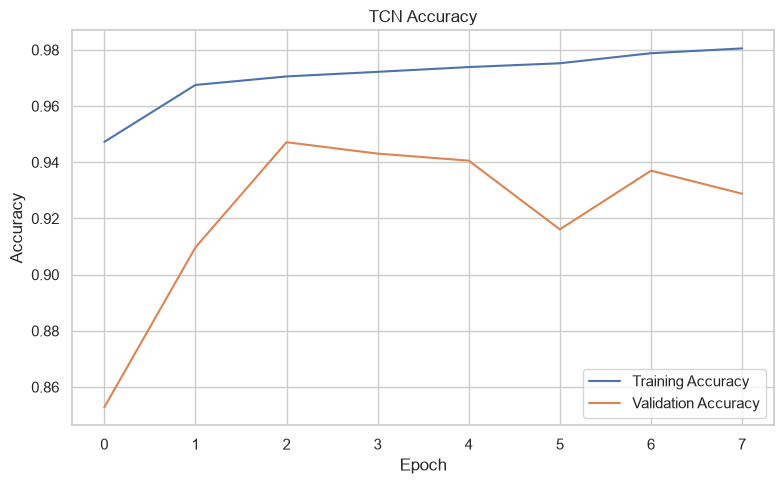

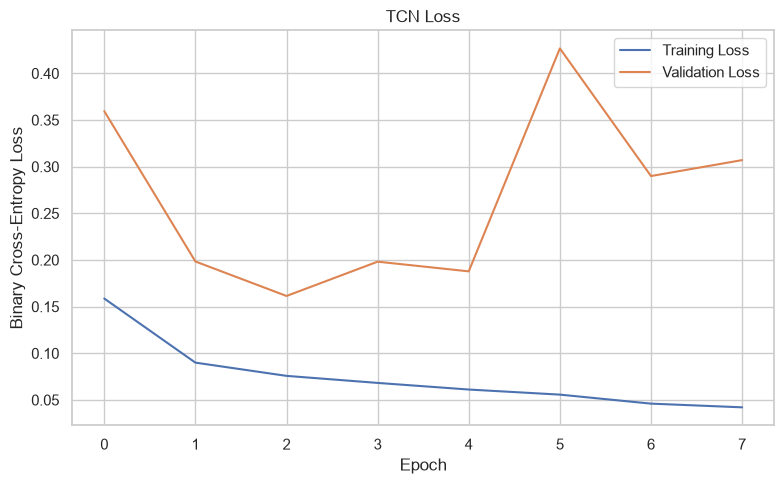

In [37]:
plot_training_history(
    tcn_history,
    "TCN"
)

TCN Validation Evaluation

In [38]:
(
    tcn_metrics,
    tcn_val_pred,
    tcn_val_prob
) = evaluate_binary_model(
    tcn_model,
    X_val,
    y_val,
    "TCN"
)

tcn_metrics[
    "Training_Time_sec"
] = tcn_training_time

pd.DataFrame(
    [tcn_metrics]
).T

,0
Model,TCN
Accuracy,0.947135
Precision,0.944418
Recall,0.981792
F1,0.962743
MCC,0.873834
FPR,0.132092
FNR,0.018208
ROC_AUC,0.973597
PR_AUC,0.986896


TCN Classification Report

In [39]:
print(
    classification_report(
        y_val,
        tcn_val_pred,
        labels=[0, 1],
        target_names=[
            "Normal",
            "DoW"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal     0.9542    0.8679    0.9090      8865
         DoW     0.9444    0.9818    0.9627     20266

    accuracy                         0.9471     29131
   macro avg     0.9493    0.9248    0.9359     29131
weighted avg     0.9474    0.9471    0.9464     29131



TCN Confusion Matrix

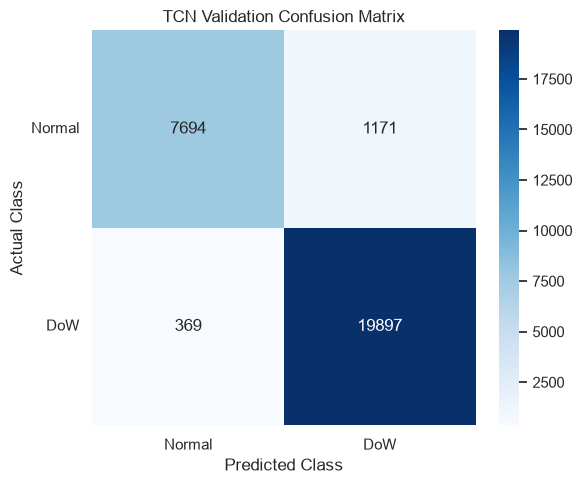

In [40]:
plot_confusion_matrix(
    y_val,
    tcn_val_pred,
    "TCN Validation"
)

# Model Comparison and Experimental Selection

The three temporal models are compared using the same validation sequences,
preprocessing pipeline and classification threshold.

The comparison considers both detection performance and computational efficiency.

Comparison Table

In [41]:
comparison_df = pd.DataFrame([
    lstm_metrics,
    gru_metrics,
    tcn_metrics
])

comparison_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "MCC",
    "FPR",
    "FNR",
    "ROC_AUC",
    "PR_AUC",
    "Latency_per_Sample_ms",
    "Training_Time_sec",
    "Parameters"
]

comparison_df[
    comparison_columns
].round(6)

,Model,Accuracy,Precision,Recall,F1,MCC,FPR,FNR,ROC_AUC,PR_AUC,Latency_per_Sample_ms,Training_Time_sec,Parameters
0,LSTM,0.949401,0.972683,0.954061,0.963282,0.882377,0.061252,0.045939,0.988708,0.994523,0.154993,852.328484,36801
1,GRU,0.946552,0.935762,0.991217,0.962691,0.873253,0.155556,0.008783,0.981393,0.990800,0.721506,592.927391,28161
2,TCN,0.947135,0.944418,0.981792,0.962743,0.873834,0.132092,0.018208,0.973597,0.986896,0.183363,745.547209,97409


Save Model Comparison

In [42]:
comparison_df.to_csv(
    RESULTS_DIR
    / "model_comparison_validation.csv",
    index=False
)

print(
    "Validation comparison saved successfully."
)

Validation comparison saved successfully.


Detection Metric Comparison Plot

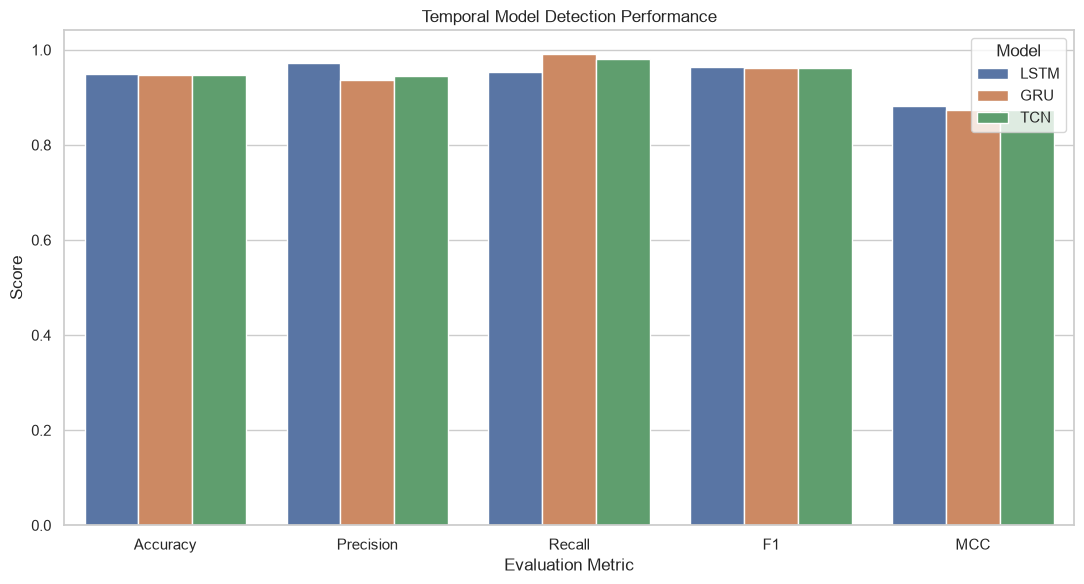

In [43]:
performance_plot_df = (
    comparison_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "MCC"
        ]
    ]
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=performance_plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title(
    "Temporal Model Detection Performance"
)

plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

FPR and FNR Comparison

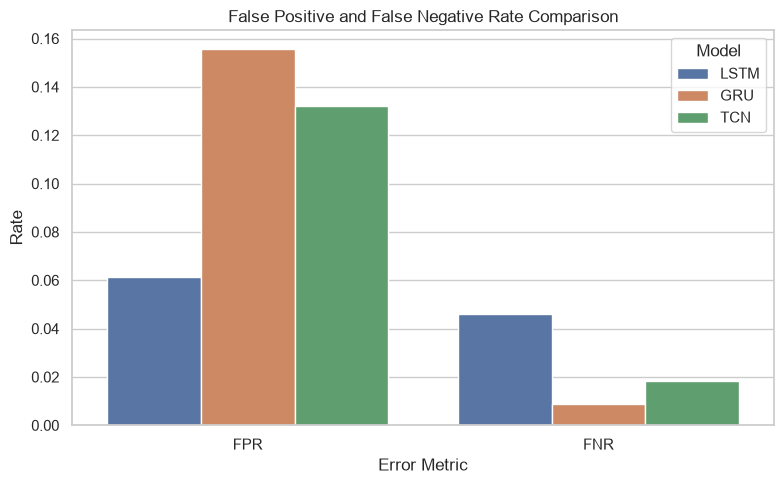

In [44]:
error_df = (
    comparison_df[
        [
            "Model",
            "FPR",
            "FNR"
        ]
    ]
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Rate"
    )
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_df,
    x="Metric",
    y="Rate",
    hue="Model"
)

plt.title(
    "False Positive and False Negative Rate Comparison"
)

plt.xlabel("Error Metric")
plt.ylabel("Rate")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

ROC Curves

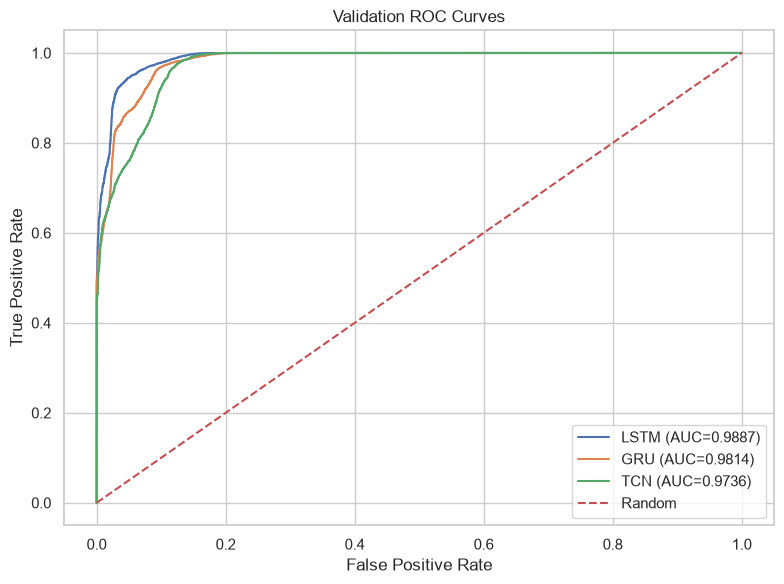

In [45]:
validation_probabilities = {
    "LSTM": lstm_val_prob,
    "GRU": gru_val_prob,
    "TCN": tcn_val_prob
}

plt.figure(figsize=(8, 6))

for model_name, probabilities in (
    validation_probabilities.items()
):

    fpr_values, tpr_values, _ = (
        roc_curve(
            y_val,
            probabilities
        )
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr_values,
        tpr_values,
        label=(
            f"{model_name} "
            f"(AUC={auc_value:.4f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.title(
    "Validation ROC Curves"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.tight_layout()
plt.show()

Precision-Recall Curves

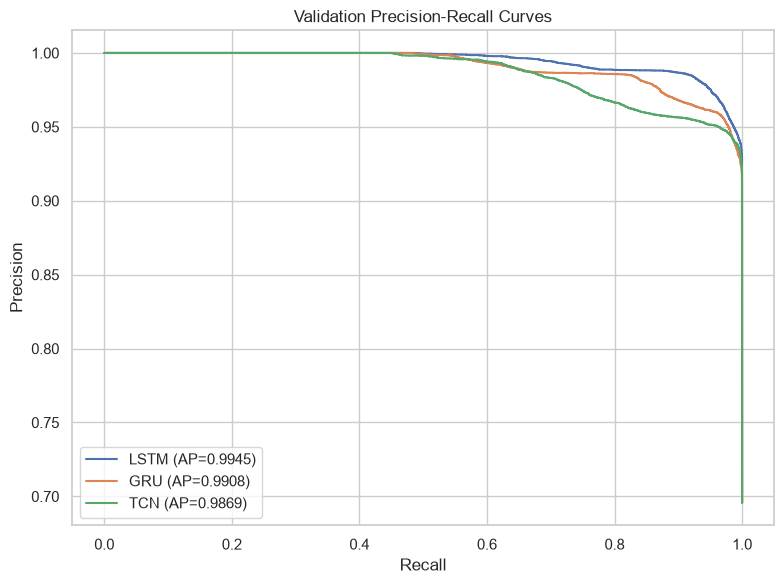

In [46]:
plt.figure(figsize=(8, 6))

for model_name, probabilities in (
    validation_probabilities.items()
):

    precision_values, recall_values, _ = (
        precision_recall_curve(
            y_val,
            probabilities
        )
    )

    ap_value = average_precision_score(
        y_val,
        probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        label=(
            f"{model_name} "
            f"(AP={ap_value:.4f})"
        )
    )

plt.title(
    "Validation Precision-Recall Curves"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()

plt.tight_layout()
plt.show()

Latency Comparison

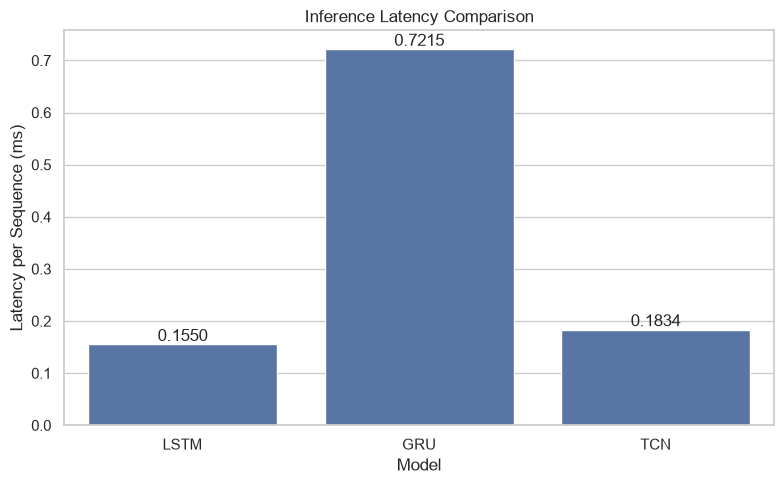

In [47]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=comparison_df,
    x="Model",
    y="Latency_per_Sample_ms"
)

plt.title(
    "Inference Latency Comparison"
)

plt.xlabel("Model")
plt.ylabel(
    "Latency per Sequence (ms)"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f"
    )

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Parameter Count Comparison

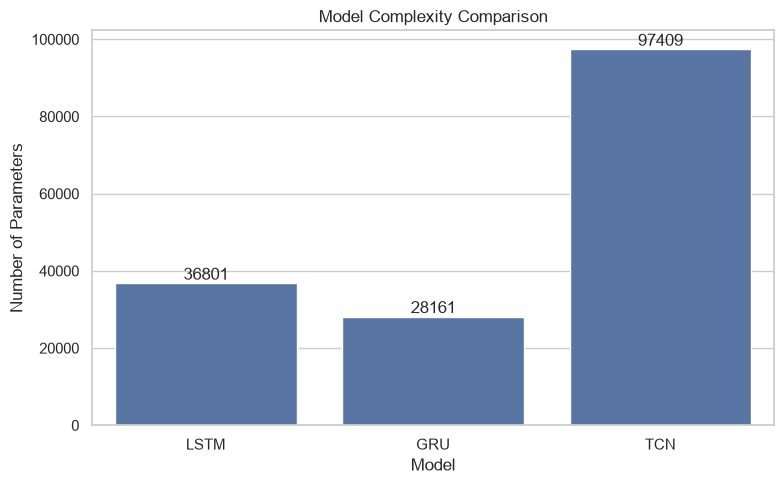

In [48]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=comparison_df,
    x="Model",
    y="Parameters"
)

plt.title(
    "Model Complexity Comparison"
)

plt.xlabel("Model")
plt.ylabel("Number of Parameters")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Training Time Comparison

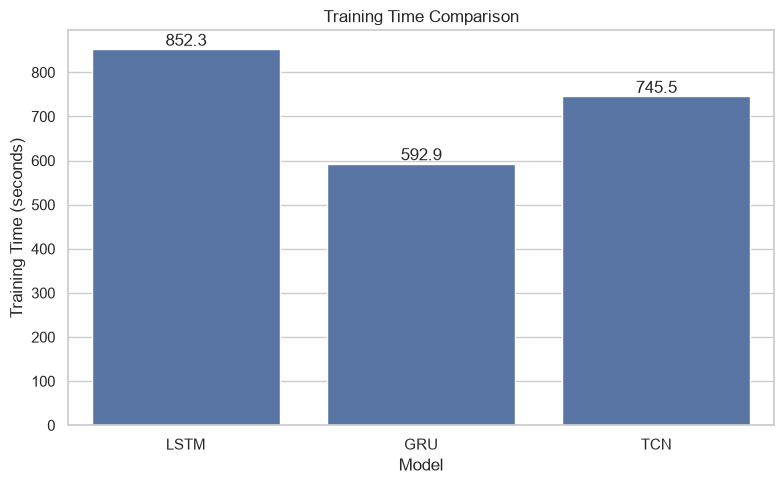

In [49]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=comparison_df,
    x="Model",
    y="Training_Time_sec"
)

plt.title(
    "Training Time Comparison"
)

plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f"
    )

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Performance-Efficiency Ranking

In [50]:

# ============================================================
# REPRODUCIBLE PERFORMANCE-BASED MODEL SELECTION
# ============================================================

selection_df = comparison_df.copy()

# Primary criterion: MCC
# Secondary criterion: F1
# Third criterion: Recall
# Final tie-breaker: fixed model name

selection_df = (
    selection_df
    .sort_values(
        by=[
            "MCC",
            "F1",
            "Recall",
            "Model"
        ],
        ascending=[
            False,
            False,
            False,
            True
        ],
        kind="stable"
    )
    .reset_index(drop=True)
)

selection_df["Selection_Rank"] = (
    np.arange(1, len(selection_df) + 1)
)

selection_df["Overall_Rank_Score"] = (
    selection_df["Selection_Rank"]
)

print("=" * 65)
print("PERFORMANCE-BASED MODEL SELECTION")
print("=" * 65)

print(
    "Primary: MCC | Secondary: F1 | "
    "Third: Recall"
)

print(
    "Latency and parameter count remain "
    "reported efficiency metrics."
)

display(
    selection_df[
        [
            "Selection_Rank",
            "Model",
            "Accuracy",
            "MCC",
            "F1",
            "Recall",
            "Latency_per_Sample_ms",
            "Parameters"
        ]
    ].round(6)
)

print(
    "\nBest model:",
    selection_df.iloc[0]["Model"]
)


PERFORMANCE-BASED MODEL SELECTION
Primary: MCC | Secondary: F1 | Third: Recall
Latency and parameter count remain reported efficiency metrics.


,Selection_Rank,Model,Accuracy,MCC,F1,Recall,Latency_per_Sample_ms,Parameters
0,1,LSTM,0.949401,0.882377,0.963282,0.954061,0.154993,36801
1,2,TCN,0.947135,0.873834,0.962743,0.981792,0.183363,97409
2,3,GRU,0.946552,0.873253,0.962691,0.991217,0.721506,28161



Best model: LSTM


Select Suitable Model

In [51]:
selected_model_name = (
    selection_df
    .iloc[0]["Model"]
)

print(
    "Experimentally selected temporal model:",
    selected_model_name
)

Experimentally selected temporal model: LSTM


Retrieve Selected Model

In [52]:
trained_models = {
    "LSTM": lstm_model,
    "GRU": gru_model,
    "TCN": tcn_model
}

selected_model = trained_models[
    selected_model_name
]

print(
    "Selected model:",
    selected_model_name
)

Selected model: LSTM


Save Selected Base Model

In [53]:
selected_base_model_path = (
    MODELS_DIR
    / "selected_base_model.keras"
)

selected_model.save(
    selected_base_model_path
)

print(
    "Selected base model saved to:",
    selected_base_model_path
)

Selected base model saved to: models\selected_base_model.keras


# Workload Distribution Shift Detection

This section investigates whether the workload feature distributions differ between the training functions and the held-out validation functions.

The Kolmogorov–Smirnov (KS) two-sample test is applied to sequence-level numerical feature summaries.

To identify meaningful distribution differences:

- Bonferroni-corrected statistical significance is considered.
- A minimum KS statistic of 0.10 is required.
- Features exceeding both thresholds are identified as exhibiting distribution shift.

**Evaluation protocol:** The dataset uses FunctionId-disjoint training, validation, and testing partitions. Therefore, this experiment measures cross-function workload distribution shift rather than globally chronological concept drift.

The validation partition was previously used for model selection. Consequently, the drift results are exploratory diagnostics and must not independently justify model adaptation using the same validation data.

The final test dataset remains untouched during this analysis.

Create Sequence-Level Feature Summaries

In [54]:
X_train_summary = (
    X_train.mean(axis=1)
)

X_val_summary = (
    X_val.mean(axis=1)
)

print(
    "Training summary:",
    X_train_summary.shape
)

print(
    "Validation summary:",
    X_val_summary.shape
)

assert (
    X_train_summary.shape[1]
    == len(feature_names)
)

print(
    "Feature-name alignment verified."
)

Training summary: (124596, 26)
Validation summary: (29131, 26)
Feature-name alignment verified.


Drift Detection Function

In [55]:
def detect_feature_drift(
    reference_data,
    current_data,
    feature_names,
    alpha=0.01,
    min_ks=0.10
):

    number_of_features = len(
        feature_names
    )

    corrected_alpha = (
        alpha / number_of_features
    )

    drift_results = []

    for i, feature in enumerate(
        feature_names
    ):

        ks_statistic, p_value = (
            ks_2samp(
                reference_data[:, i],
                current_data[:, i]
            )
        )

        drift_detected = (
            p_value
            < corrected_alpha
            and
            ks_statistic
            >= min_ks
        )

        drift_results.append({

            "Feature":
                feature,

            "KS_Statistic":
                ks_statistic,

            "P_Value":
                p_value,

            "Corrected_Alpha":
                corrected_alpha,

            "Meaningful_Drift":
                drift_detected
        })

    return pd.DataFrame(
        drift_results
    )

Run Drift Detection

In [56]:
drift_df = detect_feature_drift(
    X_train_summary,
    X_val_summary,
    feature_names,
    alpha=0.01,
    min_ks=0.10
)

drift_df.head()

,Feature,KS_Statistic,P_Value,Corrected_Alpha,Meaningful_Drift
0,numeric__RTT,0.528532,0.0,0.000385,True
1,numeric__InvocationDelay,0.423486,0.0,0.000385,True
2,numeric__ResponseDelay,0.404588,0.0,0.000385,True
3,numeric__FunctionDuration,0.453096,0.0,0.000385,True
4,numeric__ActiveFunctionsAtRequest,0.363832,0.0,0.000385,True


Drift Summary

In [57]:
number_drifted = int(
    drift_df[
        "Meaningful_Drift"
    ].sum()
)

total_features = len(
    drift_df
)

drift_percentage = (
    number_drifted
    / total_features
    * 100
)

print(
    "Features with meaningful drift:",
    number_drifted
)

print(
    "Total encoded features:",
    total_features
)

print(
    "Drift percentage:",
    round(
        drift_percentage,
        2
    ),
    "%"
)

Features with meaningful drift: 19
Total encoded features: 26
Drift percentage: 73.08 %


Strongest Drift Features

In [58]:
drift_ranked = (
    drift_df
    .sort_values(
        "KS_Statistic",
        ascending=False
    )
    .reset_index(drop=True)
)

drift_ranked.head(15)

,Feature,KS_Statistic,P_Value,Corrected_Alpha,Meaningful_Drift
0,numeric__RTT,0.528532,0.0,0.000385,True
1,numeric__TotalProcessingTime,0.528532,0.0,0.000385,True
2,numeric__FunctionDuration,0.453096,0.0,0.000385,True
3,categorical__vmcategory_Delay-insensitive,0.444685,0.0,0.000385,True
4,numeric__InvocationDelay,0.423486,0.0,0.000385,True
5,numeric__p95maxcpu,0.421361,0.0,0.000385,True
6,numeric__ResponseDelay,0.404588,0.0,0.000385,True
7,numeric__ActiveFunctionChange,0.363832,0.0,0.000385,True
8,numeric__ActiveFunctionsAtRequest,0.363832,0.0,0.000385,True
9,numeric__TotalDelay,0.353058,0.0,0.000385,True


Drift Visualization

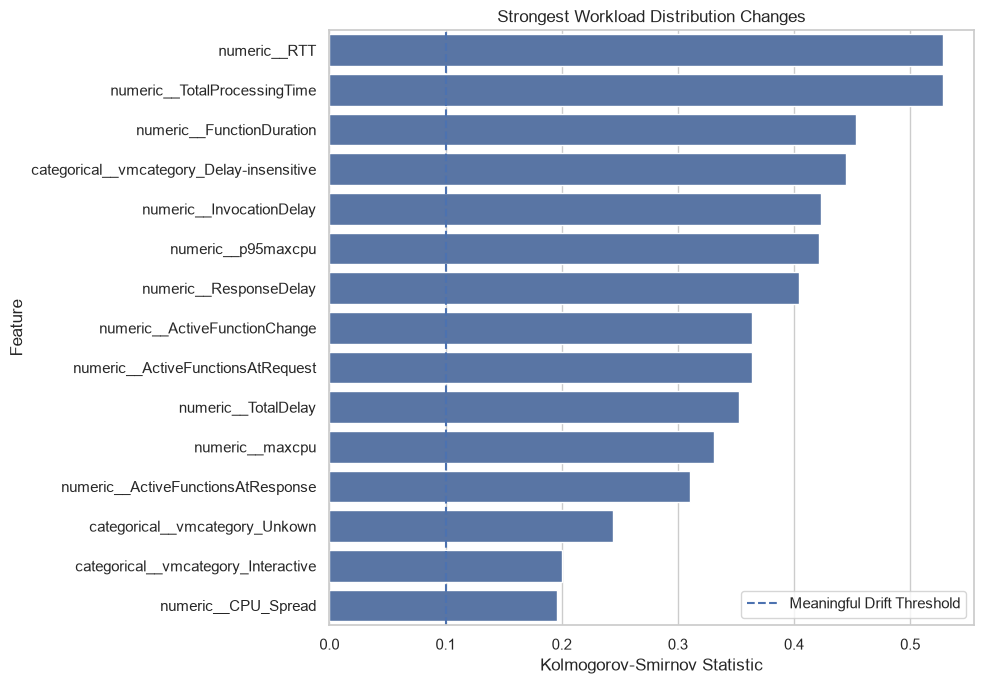

In [59]:
top_drift = (
    drift_ranked
    .head(15)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_drift,
    y="Feature",
    x="KS_Statistic"
)

plt.axvline(
    0.10,
    linestyle="--",
    label="Meaningful Drift Threshold"
)

plt.title(
    "Strongest Workload Distribution Changes"
)

plt.xlabel("Kolmogorov-Smirnov Statistic")
plt.ylabel("Feature")

plt.legend()

plt.tight_layout()
plt.show()

Save Drift Report

In [60]:
drift_df.to_csv(
    RESULTS_DIR
    / "feature_drift_report.csv",
    index=False
)

print(
    "Feature drift report saved."
)

Feature drift report saved.


# Cross-Function Distribution-Shift Adaptation

The experimentally selected LSTM is used for a supplementary model-adaptation experiment.

The training and validation functions have different workload feature distributions, as measured by the Kolmogorov–Smirnov test.

**Adaptation procedure:**

1. Retain the selected base LSTM without modifying its parameters.
2. Use the observed cross-function distribution differences to determine whether the predefined adaptation trigger is met.
3. Create a separate copy of the selected base LSTM.
4. Fine-tune the copied model using labeled observations from the validation functions.
5. Monitor adaptation training loss and apply early stopping.
6. Save the adapted LSTM separately.
7. Evaluate both the original and adapted LSTM on the same untouched test functions in the final evaluation stage.

**Evaluation limitation:** The validation functions were previously used for model selection. The adaptation results therefore represent a post-selection fine-tuning experiment, not independently validated chronological concept-drift adaptation. The test functions are not used for training, tuning, or adaptation.

Normal and DoW observations were also collected on different dates, so collection-period confounding remains a limitation.

Pre-Adaptation Final Test Performance

In [61]:

# ============================================================
# PRESERVE SELECTED BASE MODEL FOR FINAL EVALUATION
# ============================================================

from pathlib import Path

selected_base_model_path = (
    MODELS_DIR / "selected_base_model.keras"
)

assert selected_base_model_path.exists(), (
    "Selected base model checkpoint not found."
)

assert selected_model_name in ["LSTM", "GRU", "TCN"], (
    f"Unexpected selected model: {selected_model_name}"
)

print("=" * 65)
print("BASE MODEL PRESERVATION CHECK")
print("=" * 65)

print("Selected model:", selected_model_name)
print("Base checkpoint:", selected_base_model_path)

print("\nFinal test evaluation is deferred.")
print("X_test and y_test will remain unused during adaptation.")
print("Base model weights will remain unchanged.")


BASE MODEL PRESERVATION CHECK
Selected model: LSTM
Base checkpoint: models\selected_base_model.keras

Final test evaluation is deferred.
X_test and y_test will remain unused during adaptation.
Base model weights will remain unchanged.


Determine Whether Adaptation Is Required

In [62]:

# ============================================================
# CROSS-FUNCTION ADAPTATION TRIGGER
# ============================================================

DRIFT_FEATURE_THRESHOLD_PERCENT = 10.0

observed_shift_percentage = float(drift_percentage)

adaptation_required = (
    observed_shift_percentage
    >= DRIFT_FEATURE_THRESHOLD_PERCENT
)

print("=" * 65)
print("CROSS-FUNCTION ADAPTATION DECISION")
print("=" * 65)

print("Selected model:", selected_model_name)
print("Total encoded features:", total_features)
print("Shifted features:", number_drifted)

print(
    "Observed shifted-feature percentage:",
    round(observed_shift_percentage, 2),
    "%"
)

print(
    "Experimental adaptation threshold:",
    DRIFT_FEATURE_THRESHOLD_PERCENT,
    "%"
)

print("Adaptation triggered:", adaptation_required)

print("\nMethodological note:")
print(
    "This trigger measures cross-function feature "
    "distribution differences, not chronological "
    "concept drift."
)

if adaptation_required:
    print(
        f"\nDecision: Proceed with supplementary "
f"{selected_model_name} fine-tuning."
    )
else:
    print(
        "\nDecision: Retain the selected base model."
    )


CROSS-FUNCTION ADAPTATION DECISION
Selected model: LSTM
Total encoded features: 26
Shifted features: 19
Observed shifted-feature percentage: 73.08 %
Experimental adaptation threshold: 10.0 %
Adaptation triggered: True

Methodological note:
This trigger measures cross-function feature distribution differences, not chronological concept drift.

Decision: Proceed with supplementary LSTM fine-tuning.


Clone Selected Model

In [63]:
adaptive_model = tf.keras.models.clone_model(
    selected_model
)

adaptive_model.set_weights(
    selected_model.get_weights()
)

adaptive_model.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print(
    "Adaptive model copy created."
)

Adaptive model copy created.


Adapt Selected Model if Drift Exists

In [64]:

# ============================================================
# SELECTED LSTM - CROSS-FUNCTION FINE-TUNING
# ============================================================

import time
import numpy as np

ADAPTATION_EPOCHS = 10

adaptation_time = 0.0
adaptation_history = None

assert selected_model_name in ["LSTM", "GRU", "TCN"], (
    f"Unexpected selected model: {selected_model_name}"
)

assert X_val.shape[1:] == X_train.shape[1:]
assert len(X_val) == len(y_val)

assert set(np.unique(y_val).tolist()) == {0, 1}

assert np.isfinite(X_val).all()

print("=" * 65)
print(f"SELECTED {selected_model_name} ADAPTATION")
print("=" * 65)

print("Adaptation input:", X_val.shape)
print("Adaptation labels:", y_val.shape)
print("Adaptation triggered:", adaptation_required)

print(
    "\nNOTE: These validation functions were "
    "previously used for model selection."
)

print(
    "This is post-selection cross-function "
    "fine-tuning, not independent temporal adaptation."
)

if adaptation_required:

    adaptation_callbacks = [
        EarlyStopping(
            monitor="loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

    start_time = time.perf_counter()

    adaptation_history = adaptive_model.fit(
        X_val,
        y_val,
        epochs=ADAPTATION_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=adaptation_callbacks,
        shuffle=True,
        verbose=1
    )

    adaptation_time = (
        time.perf_counter() - start_time
    )

    print("\nAdaptation completed.")
    print(
        "Adaptation time:",
        round(adaptation_time, 2),
        "seconds"
    )

else:
    print(
        "Adaptation trigger not met. "
        "Base model weights retained."
    )

print("\nFinal test data has not been accessed.")


SELECTED LSTM ADAPTATION
Adaptation input: (29131, 30, 26)
Adaptation labels: (29131,)
Adaptation triggered: True

NOTE: These validation functions were previously used for model selection.
This is post-selection cross-function fine-tuning, not independent temporal adaptation.
Epoch 1/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.9510 - loss: 0.1226 - learning_rate: 1.0000e-04
Epoch 2/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9586 - loss: 0.0959 - learning_rate: 1.0000e-04
Epoch 3/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9597 - loss: 0.0882 - learning_rate: 1.0000e-04
Epoch 4/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9615 - loss: 0.0811 - learning_rate: 1.0000e-04
Epoch 5/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9616 - loss: 0.0771 - learning_rate: 1.0000e-04
Epoch 6/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9634 - loss: 0.0751 - learning_rate: 1.0000e-04
Epoch 7/10
114/114 ━━━━━━━━━━━━━

Define Final Model Label

In [65]:
if adaptation_required:
    final_model_label = (
        selected_model_name
        + "_After_Adaptation"
    )
else:
    final_model_label = (
        selected_model_name
        + "_No_Adaptation_Required"
    )

print(
    "Final model label:",
    final_model_label
)

Final model label: LSTM_After_Adaptation


Adaptation Training Plot

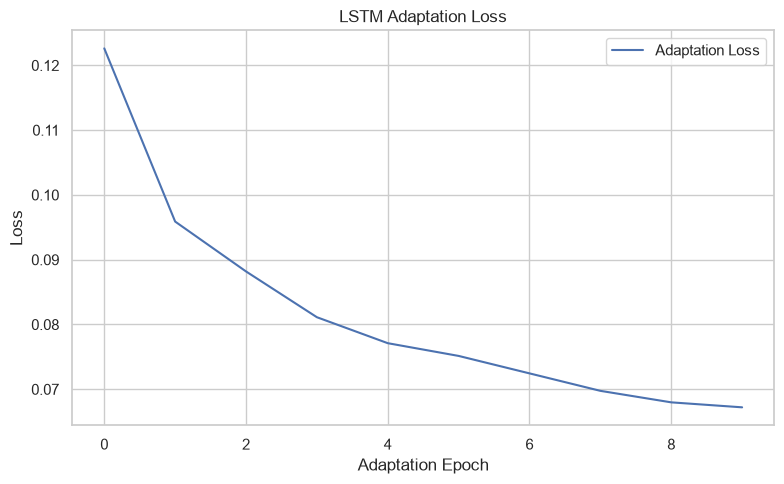

In [66]:
if adaptation_history is not None:

    adaptation_history_df = (
        pd.DataFrame(
            adaptation_history.history
        )
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        adaptation_history_df[
            "loss"
        ],
        label="Adaptation Loss"
    )

    plt.title(
        f"{selected_model_name} Adaptation Loss"
    )

    plt.xlabel("Adaptation Epoch")
    plt.ylabel("Loss")

    plt.legend()

    plt.tight_layout()
    plt.show()

else:

    print(
        "No adaptation training curve because adaptation was not required."
    )

Save Adaptive Model

In [67]:
adaptive_model_path = (
    MODELS_DIR
    / "selected_adaptive_model.keras"
)

adaptive_model.save(
    adaptive_model_path
)

print(
    "Final adaptive model saved to:",
    adaptive_model_path
)

Final adaptive model saved to: models\selected_adaptive_model.keras


# Final Cross-Function Evaluation

This section evaluates the selected base LSTM and the fine-tuned LSTM using the same untouched FunctionId-disjoint test dataset.

The final evaluation includes:

1. Accuracy, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).
2. False Positive Rate (FPR) and False Negative Rate (FNR).
3. ROC-AUC and PR-AUC.
4. Confusion matrices and classification reports.
5. Inference latency and model parameter count.
6. Before-versus-after adaptation comparison.
7. Saving the final evaluation results and visualizations.

**Evaluation protocol:** Seven held-out FunctionIds are used for testing. Neither the original LSTM training nor the supplementary fine-tuning procedure used these test functions.

**Research limitation:** This is a cross-function supervised binary classification and post-selection adaptation experiment. It does not demonstrate globally chronological future-workload detection or independently validated temporal concept-drift adaptation. Normal and DoW observations were collected on different dates.

Evaluate Final Adaptive Model

In [68]:

# ============================================================
# FINAL CROSS-FUNCTION TEST EVALUATION
# Base LSTM vs Adapted LSTM
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

print("=" * 70)
print(
    f"FINAL TEST: BASE {selected_model_name} "
    f"VS ADAPTED {selected_model_name}"
)
print("=" * 70)

# 1. Check model files
base_model_path = MODELS_DIR / "selected_base_model.keras"
adaptive_model_path = MODELS_DIR / "selected_adaptive_model.keras"

assert base_model_path.exists(), "Selected base model missing."
assert adaptive_model_path.exists(), "Selected adapted model missing."

# 2. Verify final test dataset
assert X_test.shape == (30768, 30, 26)
assert len(y_test) == len(X_test)
assert set(np.unique(y_test).tolist()) == {0, 1}
assert np.isfinite(X_test).all()

# 3. Load the saved models
base_final_model = tf.keras.models.load_model(
    base_model_path,
    compile=False
)

adapted_final_model = tf.keras.models.load_model(
    adaptive_model_path,
    compile=False
)

assert base_final_model.input_shape[1:] == X_test.shape[1:]
assert adapted_final_model.input_shape[1:] == X_test.shape[1:]

# 4. Evaluate selected base model
(
    baseline_test_metrics,
    baseline_test_pred,
    baseline_test_prob
) = evaluate_binary_model(
    base_final_model,
    X_test,
    y_test,
    f"{selected_model_name}_Before_Adaptation"
)

# 5. Evaluate selected adapted model
(
    adapted_test_metrics,
    adapted_test_pred,
    adapted_test_prob
) = evaluate_binary_model(
    adapted_final_model,
    X_test,
    y_test,
    f"{selected_model_name}_After_Adaptation"
)


# 6. Generate comparison
final_test_comparison = pd.DataFrame([
    baseline_test_metrics,
    adapted_test_metrics
])

print("\nFINAL TEST COMPARISON")

display(
    final_test_comparison[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "MCC",
            "FPR",
            "FNR",
            "ROC_AUC",
            "PR_AUC",
            "Latency_per_Sample_ms",
            "Parameters"
        ]
    ].round(6)
)

print("\nBoth models evaluated on the same held-out test set.")


FINAL TEST: BASE LSTM VS ADAPTED LSTM

FINAL TEST COMPARISON


,Model,Accuracy,Precision,Recall,F1,MCC,FPR,FNR,ROC_AUC,PR_AUC,Latency_per_Sample_ms,Parameters
0,LSTM_Before_Adaptation,0.923134,0.954335,0.927498,0.940725,0.832169,0.085248,0.072502,0.969091,0.978842,0.195995,36801
1,LSTM_After_Adaptation,0.927977,0.955000,0.934516,0.944647,0.842027,0.084583,0.065484,0.975461,0.984312,0.188074,36801



Both models evaluated on the same held-out test set.


Final Classification Report

In [69]:

# ============================================================
# CLASSIFICATION REPORTS - BEFORE VS AFTER ADAPTATION
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print(f"BASE {selected_model_name} - FINAL TEST CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        baseline_test_pred,
        labels=[0, 1],
        target_names=["Normal", "DoW"],
        digits=4,
        zero_division=0
    )
)

print("\n" + "=" * 70)
print(f"ADAPTED {selected_model_name} - FINAL TEST CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        adapted_test_pred,
        labels=[0, 1],
        target_names=["Normal", "DoW"],
        digits=4,
        zero_division=0
    )
)


BASE LSTM - FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.8679    0.9148    0.8907     10534
         DoW     0.9543    0.9275    0.9407     20234

    accuracy                         0.9231     30768
   macro avg     0.9111    0.9211    0.9157     30768
weighted avg     0.9247    0.9231    0.9236     30768


ADAPTED LSTM - FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.8792    0.9154    0.8969     10534
         DoW     0.9550    0.9345    0.9446     20234

    accuracy                         0.9280     30768
   macro avg     0.9171    0.9250    0.9208     30768
weighted avg     0.9290    0.9280    0.9283     30768



Final Confusion Matrix

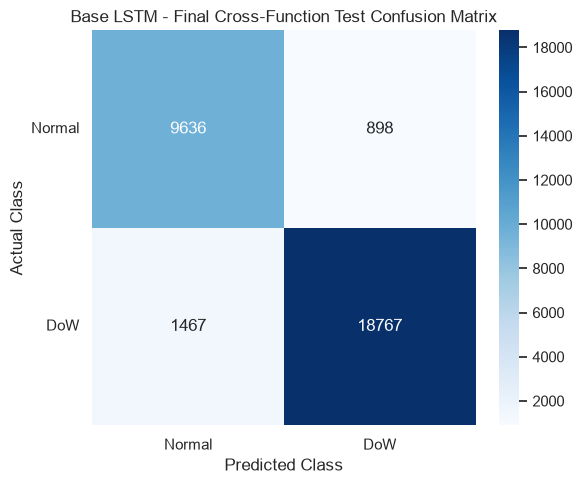

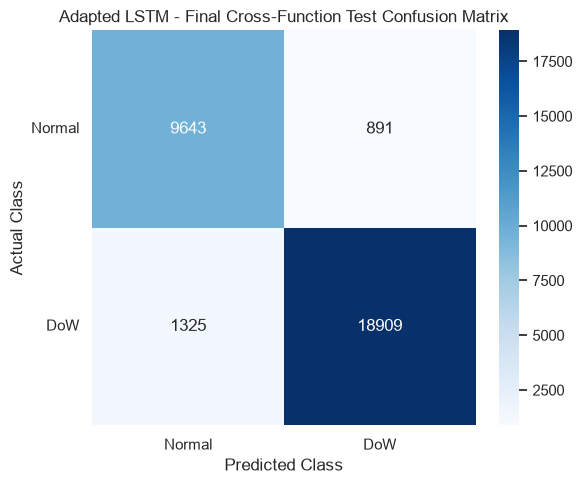

Both final confusion matrices generated.


In [70]:

# ============================================================
# CONFUSION MATRICES - BEFORE VS AFTER ADAPTATION
# ============================================================

plot_confusion_matrix(
    y_test,
    baseline_test_pred,
    f"Base {selected_model_name} - Final Cross-Function Test"
)

plot_confusion_matrix(
    y_test,
    adapted_test_pred,
    f"Adapted {selected_model_name} - Final Cross-Function Test"
)

print("Both final confusion matrices generated.")


Before vs After Adaptation Table

In [71]:
adaptation_comparison = pd.DataFrame([
    baseline_test_metrics,
    adapted_test_metrics
])

adaptation_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "MCC",
        "FPR",
        "FNR",
        "ROC_AUC",
        "PR_AUC",
        "Latency_per_Sample_ms"
    ]
].round(6)

,Model,Accuracy,Precision,Recall,F1,MCC,FPR,FNR,ROC_AUC,PR_AUC,Latency_per_Sample_ms
0,LSTM_Before_Adaptation,0.923134,0.954335,0.927498,0.940725,0.832169,0.085248,0.072502,0.969091,0.978842,0.195995
1,LSTM_After_Adaptation,0.927977,0.955000,0.934516,0.944647,0.842027,0.084583,0.065484,0.975461,0.984312,0.188074


Adaptation Improvement Table

In [72]:
improvement_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "MCC",
    "ROC_AUC",
    "PR_AUC"
]

improvement_rows = []

for metric in improvement_metrics:

    before_value = (
        baseline_test_metrics[
            metric
        ]
    )

    after_value = (
        adapted_test_metrics[
            metric
        ]
    )

    improvement_rows.append({

        "Metric":
            metric,

        "Before_Adaptation":
            before_value,

        "After_Adaptation":
            after_value,

        "Absolute_Change":
            after_value
            - before_value
    })

improvement_df = pd.DataFrame(
    improvement_rows
)

improvement_df.round(6)

,Metric,Before_Adaptation,After_Adaptation,Absolute_Change
0,Accuracy,0.923134,0.927977,0.004843
1,Precision,0.954335,0.955000,0.000665
2,Recall,0.927498,0.934516,0.007018
3,F1,0.940725,0.944647,0.003922
4,MCC,0.832169,0.842027,0.009857
5,ROC_AUC,0.969091,0.975461,0.006370
6,PR_AUC,0.978842,0.984312,0.005471


Adaptation Performance Plot

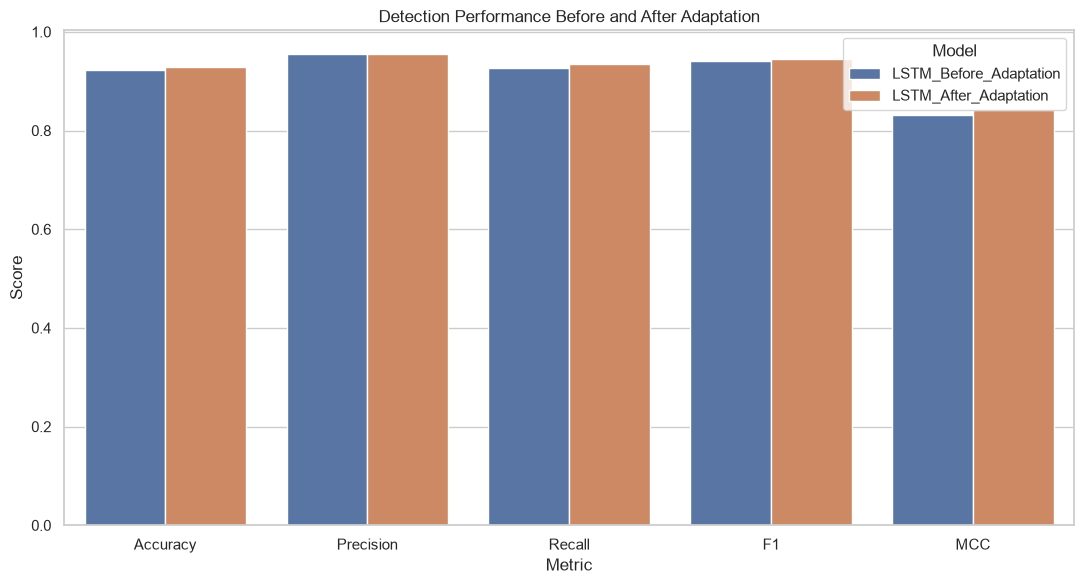

In [73]:
adaptation_plot_df = (
    adaptation_comparison[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "MCC"
        ]
    ]
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=adaptation_plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title(
    "Detection Performance Before and After Adaptation"
)

plt.xlabel("Metric")
plt.ylabel("Score")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

FPR/FNR Adaptation Comparison

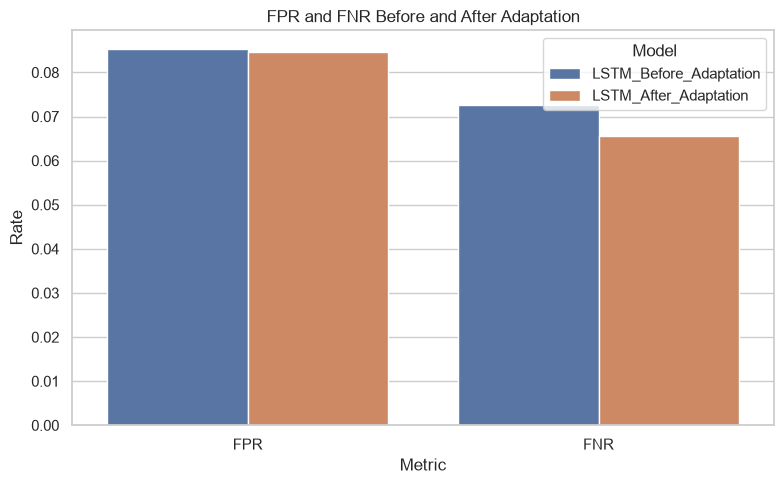

In [74]:
adaptation_error_df = (
    adaptation_comparison[
        [
            "Model",
            "FPR",
            "FNR"
        ]
    ]
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Rate"
    )
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=adaptation_error_df,
    x="Metric",
    y="Rate",
    hue="Model"
)

plt.title(
    "FPR and FNR Before and After Adaptation"
)

plt.xlabel("Metric")
plt.ylabel("Rate")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Final ROC Comparison

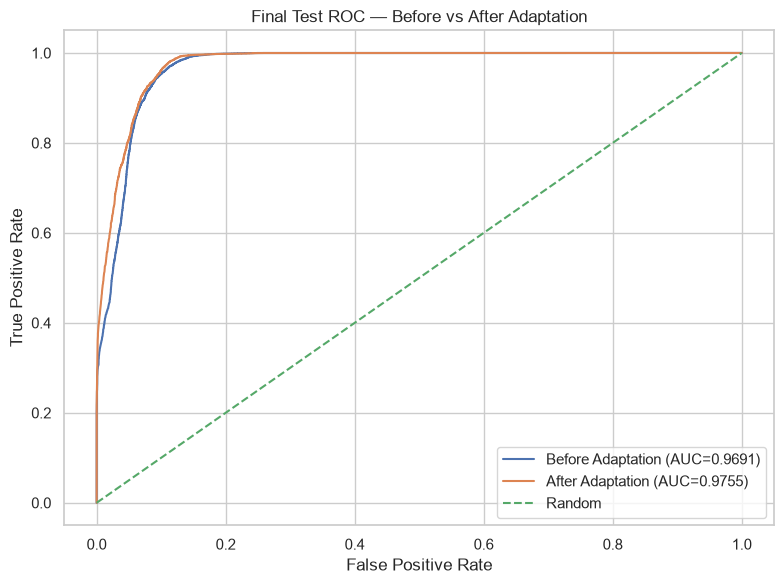

In [75]:
before_fpr, before_tpr, _ = (
    roc_curve(
        y_test,
        baseline_test_prob
    )
)

after_fpr, after_tpr, _ = (
    roc_curve(
        y_test,
        adapted_test_prob
    )
)

before_auc = roc_auc_score(
    y_test,
    baseline_test_prob
)

after_auc = roc_auc_score(
    y_test,
    adapted_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    before_fpr,
    before_tpr,
    label=(
        f"Before Adaptation "
        f"(AUC={before_auc:.4f})"
    )
)

plt.plot(
    after_fpr,
    after_tpr,
    label=(
        f"After Adaptation "
        f"(AUC={after_auc:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.title(
    "Final Test ROC — Before vs After Adaptation"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.tight_layout()
plt.show()

Final Precision-Recall Comparison

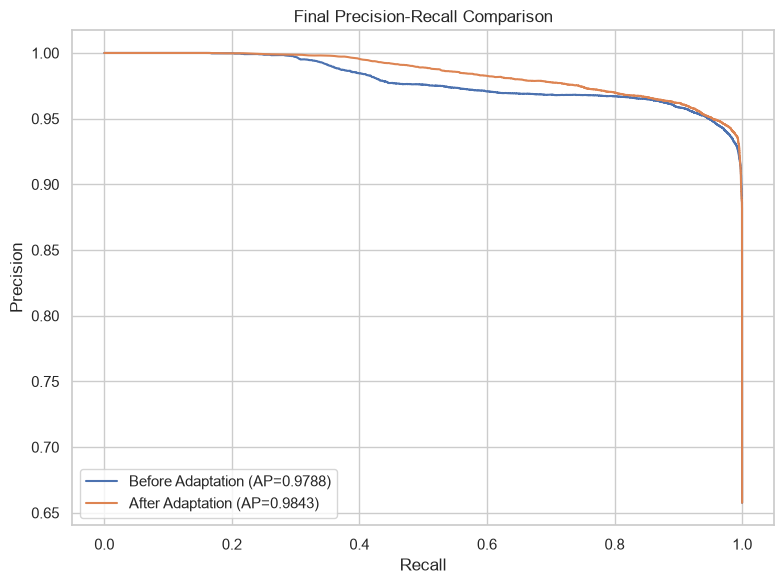

In [76]:
before_precision, before_recall, _ = (
    precision_recall_curve(
        y_test,
        baseline_test_prob
    )
)

after_precision, after_recall, _ = (
    precision_recall_curve(
        y_test,
        adapted_test_prob
    )
)

before_ap = average_precision_score(
    y_test,
    baseline_test_prob
)

after_ap = average_precision_score(
    y_test,
    adapted_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    before_recall,
    before_precision,
    label=(
        f"Before Adaptation "
        f"(AP={before_ap:.4f})"
    )
)

plt.plot(
    after_recall,
    after_precision,
    label=(
        f"After Adaptation "
        f"(AP={after_ap:.4f})"
    )
)

plt.title(
    "Final Precision-Recall Comparison"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()

plt.tight_layout()
plt.show()

Save Adaptation Results

In [77]:
adaptation_comparison.to_csv(
    RESULTS_DIR
    / "adaptation_comparison.csv",
    index=False
)

improvement_df.to_csv(
    RESULTS_DIR
    / "adaptation_improvement.csv",
    index=False
)

print(
    "Adaptation evaluation files saved."
)

Adaptation evaluation files saved.


Create Final Results Table

In [78]:
final_results = pd.DataFrame({

    "Selected_Model": [
        selected_model_name
    ],

    "Adaptation_Required": [
        adaptation_required
    ],

    "Final_Accuracy": [
        adapted_test_metrics[
            "Accuracy"
        ]
    ],

    "Final_Precision": [
        adapted_test_metrics[
            "Precision"
        ]
    ],

    "Final_Recall": [
        adapted_test_metrics[
            "Recall"
        ]
    ],

    "Final_F1": [
        adapted_test_metrics[
            "F1"
        ]
    ],

    "Final_MCC": [
        adapted_test_metrics[
            "MCC"
        ]
    ],

    "Final_FPR": [
        adapted_test_metrics[
            "FPR"
        ]
    ],

    "Final_FNR": [
        adapted_test_metrics[
            "FNR"
        ]
    ],

    "Final_ROC_AUC": [
        adapted_test_metrics[
            "ROC_AUC"
        ]
    ],

    "Final_PR_AUC": [
        adapted_test_metrics[
            "PR_AUC"
        ]
    ],

    "Inference_Latency_ms": [
        adapted_test_metrics[
            "Latency_per_Sample_ms"
        ]
    ],

    "Parameter_Count": [
        adapted_test_metrics[
            "Parameters"
        ]
    ],

    "Drifted_Features": [
        number_drifted
    ],

    "Drift_Percentage": [
        drift_percentage
    ],

    "Adaptation_Time_sec": [
        adaptation_time
    ]
})

final_results.T

,0
Selected_Model,LSTM
Adaptation_Required,True
Final_Accuracy,0.927977
Final_Precision,0.955
Final_Recall,0.934516
Final_F1,0.944647
Final_MCC,0.842027
Final_FPR,0.084583
Final_FNR,0.065484
Final_ROC_AUC,0.975461


Save Final Results

In [79]:
final_results.to_csv(
    RESULTS_DIR
    / "final_results.csv",
    index=False
)

selection_df.to_csv(
    RESULTS_DIR
    / "model_selection_ranking.csv",
    index=False
)

print(
    "Final project results saved successfully."
)

Final project results saved successfully.


Final Experiment Summary

In [80]:
print("=" * 70)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print(
    "\nSelected temporal model:",
    selected_model_name
)

print(
    "\nMeaningful drift features:",
    number_drifted,
    "/",
    total_features
)

print(
    "Drift percentage:",
    round(
        drift_percentage,
        2
    ),
    "%"
)

print(
    "Adaptation required:",
    adaptation_required
)

print(
    "\nFINAL TEST PERFORMANCE"
)

print(
    "Accuracy :",
    round(
        adapted_test_metrics[
            "Accuracy"
        ],
        4
    )
)

print(
    "Precision:",
    round(
        adapted_test_metrics[
            "Precision"
        ],
        4
    )
)

print(
    "Recall   :",
    round(
        adapted_test_metrics[
            "Recall"
        ],
        4
    )
)

print(
    "F1       :",
    round(
        adapted_test_metrics[
            "F1"
        ],
        4
    )
)

print(
    "MCC      :",
    round(
        adapted_test_metrics[
            "MCC"
        ],
        4
    )
)

print(
    "FPR      :",
    round(
        adapted_test_metrics[
            "FPR"
        ],
        4
    )
)

print(
    "FNR      :",
    round(
        adapted_test_metrics[
            "FNR"
        ],
        4
    )
)

print(
    "ROC-AUC  :",
    round(
        adapted_test_metrics[
            "ROC_AUC"
        ],
        4
    )
)

print(
    "PR-AUC   :",
    round(
        adapted_test_metrics[
            "PR_AUC"
        ],
        4
    )
)

print(
    "\nNotebook 02 completed successfully."
)

FINAL EXPERIMENT SUMMARY

Selected temporal model: LSTM

Meaningful drift features: 19 / 26
Drift percentage: 73.08 %
Adaptation required: True

FINAL TEST PERFORMANCE
Accuracy : 0.928
Precision: 0.955
Recall   : 0.9345
F1       : 0.9446
MCC      : 0.842
FPR      : 0.0846
FNR      : 0.0655
ROC-AUC  : 0.9755
PR-AUC   : 0.9843

Notebook 02 completed successfully.


# Notebook 02 — Completed

## Temporal Deep Learning, Distribution-Shift Adaptation and Final Evaluation

This notebook successfully implements and evaluates the temporal deep-learning framework for detecting Denial-of-Wallet (DoW) attacks in serverless cloud environments.

### 1. Temporal Deep-Learning Model Training

Three deep-learning architectures were trained and evaluated using the preprocessed temporal sequences generated in Notebook 01:

- Long Short-Term Memory (LSTM)
- Gated Recurrent Unit (GRU)
- Temporal Convolutional Network (TCN)

Each model was trained using 30-step temporal sequences containing 26 encoded features. The models were evaluated on function-disjoint validation data to assess their ability to generalize to previously unseen serverless functions.

### 2. Model Comparison and Selection

The validation performance obtained during the completed execution was:

| Model | Validation Accuracy | F1-Score | MCC |
|---|---:|---:|---:|
| LSTM | **94.94%** | **0.9633** | **0.8824** |
| TCN | 94.71% | 0.9627 | 0.8738 |
| GRU | 94.66% | 0.9627 | 0.8733 |

**Selected Best Model: LSTM**

The best model was selected using a hardware-independent ranking procedure that prioritizes Matthews Correlation Coefficient (MCC), followed by F1-score and Recall. Inference latency and parameter count were retained as efficiency measurements but excluded from determining the selected model.

LSTM achieved the highest validation accuracy, F1-score and MCC in this execution.

### 3. Reproducibility Configuration

The notebook incorporates reproducibility controls, including:

- Fixed random seed configuration.
- Deterministic TensorFlow operations.
- Independent initialization seeds for LSTM, GRU and TCN.
- Consistent training configurations and evaluation procedures.
- Hardware-independent model-selection criteria.
- Model-independent adaptation and final evaluation logic.

These configurations improve experimental repeatability. However, exact numerical reproduction across different hardware or software environments is not guaranteed, and repeated-run consistency has not yet been independently verified.

### 4. Distribution-Shift Detection

A Kolmogorov–Smirnov (KS) statistical test was applied to identify differences in feature distributions between the training and held-out validation functions.

The analysis identified distribution shifts across **19 of 26 encoded features (73.08%)**.

These results indicate cross-function covariate distribution differences. They do not independently establish chronological concept drift or changes in the relationship between features and attack labels over time.

### 5. Selected-Model Adaptation

The selected LSTM model underwent supplementary cross-function fine-tuning using the validation-function sequences.

- **Selected model:** LSTM
- **Adaptation method:** Fine-tuning of the selected temporal model
- **Maximum adaptation epochs:** 10
- **Recorded adaptation time:** 35.09 seconds
- **Adaptation dataset:** Function-disjoint validation sequences

The validation functions had previously been used for model selection. Therefore, this stage is described as post-selection cross-function fine-tuning rather than independently validated future-time adaptation.

The held-out test functions were not used during adaptation.

### 6. Final Held-Out Test Evaluation

The original selected LSTM and its adapted version were evaluated on the same held-out test set.

| Evaluation Metric | Base LSTM | Adapted LSTM |
|---|---:|---:|
| Accuracy | 92.31% | **92.80%** |
| Precision | 95.43% | **95.50%** |
| Recall | 92.75% | **93.45%** |
| F1-Score | 0.9407 | **0.9446** |
| MCC | 0.8322 | **0.8420** |
| ROC-AUC | 0.9691 | **0.9755** |
| PR-AUC | 0.9788 | **0.9843** |
| False Positive Rate | 8.52% | **8.46%** |

The adapted LSTM improved test accuracy by approximately **0.49 percentage points**, with corresponding improvements in Recall, F1-score, MCC, ROC-AUC and PR-AUC.

### 7. Final Implementation Outcomes

The completed notebook demonstrates:

1. Successful training and evaluation of LSTM, GRU and TCN models for DoW attack detection.
2. Experimental selection of LSTM based on validation performance.
3. Improved repeatability through deterministic training configurations and controlled initialization.
4. Identification of cross-function feature distribution shifts.
5. Supplementary fine-tuning of the selected model.
6. Improved held-out test performance following adaptation.
7. Successful completion of the base-versus-adapted model evaluation.

### 8. Scope and Limitations

The experiment uses a FunctionId-disjoint evaluation protocol rather than a strictly future-time chronological split.

The available dataset does not support an independently validated chronological concept-drift evaluation because normal and DoW observations occur in different recording periods. Additional longitudinal workload recordings would be required to establish genuine temporal concept drift and independently evaluate future-time adaptation.

### Final Conclusion

**LSTM was selected as the best-performing temporal model**, achieving **94.94% validation accuracy**.

Following supplementary cross-function adaptation, the final LSTM achieved **92.80% accuracy, 93.45% recall and an F1-score of 0.9446** on the held-out test set.

The completed implementation demonstrates effective cross-function DoW attack classification and improved performance following adaptation, while maintaining a clear distinction between observed distribution shift and genuine chronological concept drift.

**Notebook 02 Status: Successfully Executed and Evaluated.**